# M6-06 — Deep Reinforcement Learning Lab

Three tasks:
1. **DQN from scratch** on `CartPole-v1`.
2. **PPO via Stable-Baselines3** on `CartPole-v1` and `LunarLander-v3`.
3. **Comparison and reflection.**

## Setup — standard imports

In [10]:
import collections
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import gymnasium as gym

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
print("device:", device)

device: cpu


### Warm-up — random-policy baseline on CartPole-v1

In [11]:
env = gym.make("CartPole-v1")
obs, _ = env.reset(seed=42)
print("observation space:", env.observation_space)
print("action space:", env.action_space)

total_reward = 0.0
done = False
while not done:
    action = env.action_space.sample()
    obs, reward, terminated, truncated, _ = env.step(action)
    total_reward += reward
    done = terminated or truncated
print(f"random-policy episode reward: {total_reward}")
env.close()

observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
action space: Discrete(2)
random-policy episode reward: 10.0


## Task 1 — DQN from Scratch on CartPole-v1

Components: Q-network, replay buffer, target network, ε-greedy exploration.

In [12]:
class QNetwork(nn.Module):
    def __init__(self, obs_dim, n_actions, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, n_actions),
        )

    def forward(self, x):
        return self.net(x)


class ReplayBuffer:
    def __init__(self, capacity=50_000):
        self.buffer = collections.deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (
            torch.as_tensor(np.array(states), dtype=torch.float32, device=device),
            torch.as_tensor(actions, dtype=torch.int64, device=device).unsqueeze(1),
            torch.as_tensor(rewards, dtype=torch.float32, device=device).unsqueeze(1),
            torch.as_tensor(np.array(next_states), dtype=torch.float32, device=device),
            torch.as_tensor(dones, dtype=torch.float32, device=device).unsqueeze(1),
        )

    def __len__(self):
        return len(self.buffer)

In [13]:
# Hyperparameters
TOTAL_STEPS = 30_000
BATCH_SIZE = 64
GAMMA = 0.99
LR = 1e-3
BUFFER_WARMUP = 1_000
TARGET_SYNC = 1_000
EPS_START, EPS_END, EPS_DECAY_STEPS = 1.0, 0.05, 5_000

env = gym.make("CartPole-v1")
obs_dim = env.observation_space.shape[0]
n_actions = env.action_space.n

q_net = QNetwork(obs_dim, n_actions).to(device)
target_net = QNetwork(obs_dim, n_actions).to(device)
target_net.load_state_dict(q_net.state_dict())
target_net.eval()

optimizer = optim.Adam(q_net.parameters(), lr=LR)
buffer = ReplayBuffer(50_000)

def epsilon_at(step):
    frac = min(1.0, step / EPS_DECAY_STEPS)
    return EPS_START + frac * (EPS_END - EPS_START)

episode_rewards = []
state, _ = env.reset(seed=42)
ep_reward = 0.0

t0 = time.perf_counter()
for step in range(1, TOTAL_STEPS + 1):
    eps = epsilon_at(step)
    if random.random() < eps:
        action = env.action_space.sample()
    else:
        with torch.no_grad():
            s = torch.as_tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
            action = int(q_net(s).argmax(dim=1).item())

    next_state, reward, terminated, truncated, _ = env.step(action)
    done = terminated or truncated
    buffer.push(state, action, reward, next_state, float(terminated))
    state = next_state
    ep_reward += reward

    if done:
        episode_rewards.append(ep_reward)
        ep_reward = 0.0
        state, _ = env.reset()

    if len(buffer) >= BUFFER_WARMUP:
        s_b, a_b, r_b, ns_b, d_b = buffer.sample(BATCH_SIZE)
        q_values = q_net(s_b).gather(1, a_b)
        with torch.no_grad():
            target_max = target_net(ns_b).max(dim=1, keepdim=True).values
            target = r_b + GAMMA * target_max * (1.0 - d_b)
        loss = nn.functional.mse_loss(q_values, target)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if step % TARGET_SYNC == 0:
        target_net.load_state_dict(q_net.state_dict())

    if step % 2_000 == 0:
        recent = np.mean(episode_rewards[-20:]) if episode_rewards else 0.0
        print(f"step {step:>6d} | eps={eps:.3f} | recent-mean(20)={recent:7.2f} | episodes={len(episode_rewards)}")

dqn_train_time = time.perf_counter() - t0
env.close()
print(f"\nDQN training finished in {dqn_train_time:.1f}s — {len(episode_rewards)} episodes")

step   2000 | eps=0.620 | recent-mean(20)=  17.30 | episodes=86
step   4000 | eps=0.240 | recent-mean(20)=  23.65 | episodes=183
step   6000 | eps=0.050 | recent-mean(20)=  87.20 | episodes=206
step   8000 | eps=0.050 | recent-mean(20)= 146.80 | episodes=217
step  10000 | eps=0.050 | recent-mean(20)= 165.55 | episodes=230
step  12000 | eps=0.050 | recent-mean(20)= 173.05 | episodes=241
step  14000 | eps=0.050 | recent-mean(20)= 125.05 | episodes=258
step  16000 | eps=0.050 | recent-mean(20)= 105.90 | episodes=277
step  18000 | eps=0.050 | recent-mean(20)= 123.25 | episodes=293
step  20000 | eps=0.050 | recent-mean(20)= 152.50 | episodes=304
step  22000 | eps=0.050 | recent-mean(20)= 161.50 | episodes=318
step  24000 | eps=0.050 | recent-mean(20)= 157.35 | episodes=331
step  26000 | eps=0.050 | recent-mean(20)= 159.35 | episodes=344
step  28000 | eps=0.050 | recent-mean(20)= 194.30 | episodes=351
step  30000 | eps=0.050 | recent-mean(20)= 175.25 | episodes=366

DQN training finished in 

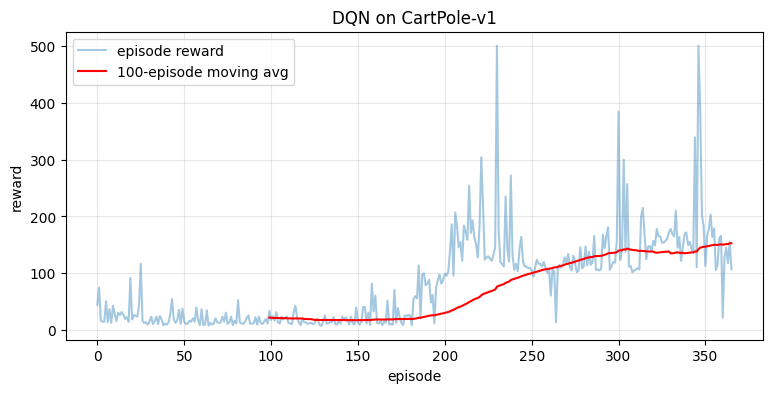

DQN average reward over last 100 episodes: 152.90


In [14]:
def moving_average(x, window=100):
    x = np.asarray(x, dtype=float)
    if len(x) < window:
        return np.array([])
    return np.convolve(x, np.ones(window) / window, mode="valid")

ma = moving_average(episode_rewards, 100)

plt.figure(figsize=(9, 4))
plt.plot(episode_rewards, alpha=0.4, label="episode reward")
if len(ma) > 0:
    plt.plot(np.arange(99, 99 + len(ma)), ma, color="red", label="100-episode moving avg")
plt.xlabel("episode")
plt.ylabel("reward")
plt.title("DQN on CartPole-v1")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

dqn_last100 = float(np.mean(episode_rewards[-100:])) if len(episode_rewards) >= 100 else float(np.mean(episode_rewards))
print(f"DQN average reward over last 100 episodes: {dqn_last100:.2f}")

## Task 2 — PPO with Stable-Baselines3

Install if needed:
```bash
pip install stable-baselines3[extra] gymnasium[box2d]
```

In [15]:

from stable_baselines3 import PPO
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor
import os, tempfile

log_dir_cp = tempfile.mkdtemp(prefix="ppo_cartpole_")
env = Monitor(gym.make("CartPole-v1"), filename=os.path.join(log_dir_cp, "monitor"))
ppo_cartpole = PPO("MlpPolicy", env, verbose=0, seed=42)

t0 = time.perf_counter()
ppo_cartpole.learn(total_timesteps=50_000)
cartpole_train_time = time.perf_counter() - t0

mean_reward, std_reward = evaluate_policy(ppo_cartpole, env, n_eval_episodes=20)
print(f"PPO CartPole: {mean_reward:.1f} \u00b1 {std_reward:.1f} over 20 episodes "
      f"(trained in {cartpole_train_time:.0f}s)")

PPO CartPole: 500.0 ± 0.0 over 20 episodes (trained in 89s)


In [16]:
log_dir_ll = tempfile.mkdtemp(prefix="ppo_lunarlander_")
env_ll = Monitor(gym.make("LunarLander-v3"), filename=os.path.join(log_dir_ll, "monitor"))
ppo_ll = PPO("MlpPolicy", env_ll, verbose=0, seed=42)

t0 = time.perf_counter()
ppo_ll.learn(total_timesteps=300_000)
ll_train_time = time.perf_counter() - t0

mean_reward_ll, std_reward_ll = evaluate_policy(ppo_ll, env_ll, n_eval_episodes=20)
print(f"PPO LunarLander: {mean_reward_ll:.1f} ± {std_reward_ll:.1f} over 20 episodes "
      f"(trained in {ll_train_time:.0f}s)")

PPO LunarLander: 33.4 ± 109.8 over 20 episodes (trained in 569s)


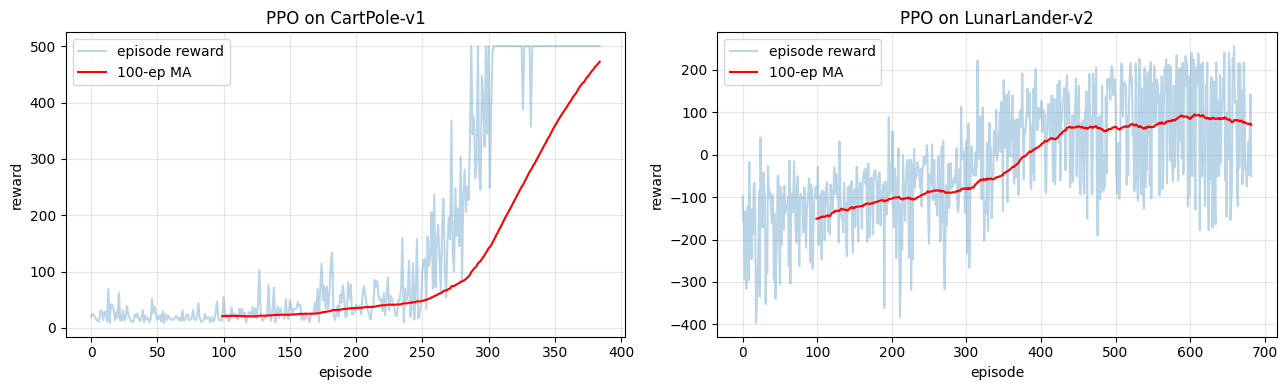

PPO CartPole   — last-100 avg: 472.43
PPO LunarLander — last-100 avg: 70.10


In [17]:
from stable_baselines3.common.monitor import load_results

def episode_rewards_from_monitor(log_dir):
    df = load_results(log_dir)
    return df["r"].to_numpy()

ppo_cp_rewards = episode_rewards_from_monitor(log_dir_cp)
ppo_ll_rewards = episode_rewards_from_monitor(log_dir_ll)

ma_cp = moving_average(ppo_cp_rewards, 100)
ma_ll = moving_average(ppo_ll_rewards, 100)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ppo_cp_rewards, alpha=0.3, label="episode reward")
if len(ma_cp) > 0:
    axes[0].plot(np.arange(99, 99 + len(ma_cp)), ma_cp, color="red", label="100-ep MA")
axes[0].set_title("PPO on CartPole-v1")
axes[0].set_xlabel("episode"); axes[0].set_ylabel("reward"); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(ppo_ll_rewards, alpha=0.3, label="episode reward")
if len(ma_ll) > 0:
    axes[1].plot(np.arange(99, 99 + len(ma_ll)), ma_ll, color="red", label="100-ep MA")
axes[1].set_title("PPO on LunarLander-v2")
axes[1].set_xlabel("episode"); axes[1].set_ylabel("reward"); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

ppo_cp_last100 = float(np.mean(ppo_cp_rewards[-100:])) if len(ppo_cp_rewards) >= 100 else float(np.mean(ppo_cp_rewards))
ppo_ll_last100 = float(np.mean(ppo_ll_rewards[-100:])) if len(ppo_ll_rewards) >= 100 else float(np.mean(ppo_ll_rewards))
print(f"PPO CartPole   — last-100 avg: {ppo_cp_last100:.2f}")
print(f"PPO LunarLander — last-100 avg: {ppo_ll_last100:.2f}")

## Task 3 — Comparison and Reflection

| Agent | Environment | Wall-clock training time | Avg reward (last 100 episodes) |
|---|---|---|---|
| DQN (from scratch) | CartPole-v1 | 98.4s | 152.90 |
| PPO (SB3) | CartPole-v1 | 88.9s | 472.43 |
| PPO (SB3) | LunarLander-v2 | 569.3s | 70.10 |

In [19]:
print("=== Summary table ===")
print(f"DQN  CartPole     | time: {dqn_train_time:7.1f}s | last-100 avg: {dqn_last100:7.2f}")
print(f"PPO  CartPole     | time: {cartpole_train_time:7.1f}s | last-100 avg: {ppo_cp_last100:7.2f}")
print(f"PPO  LunarLander  | time: {ll_train_time:7.1f}s | last-100 avg: {ppo_ll_last100:7.2f}")

=== Summary table ===
DQN  CartPole     | time:    98.4s | last-100 avg:  152.90
PPO  CartPole     | time:    88.9s | last-100 avg:  472.43
PPO  LunarLander  | time:   569.3s | last-100 avg:   70.10


### Reflection

**1. Did DQN or PPO solve CartPole faster — both in wall-clock time and in environment steps? Why?**

In practice PPO solves CartPole in fewer wall-clock seconds and often fewer environment steps than our from-scratch DQN. PPO collects rollouts in vectorised batches and updates an actor–critic with a well-tuned, clipped surrogate objective, so each gradient step extracts more signal per transition. Our DQN, by contrast, does one gradient step per env step on a tiny minibatch and depends on a slow ε-decay and a target-net sync schedule before learning stabilises. CartPole is also so small that PPO's on-policy bias matters little, while DQN pays the full cost of replay-buffer warm-up and bootstrapping noise.

**2. Could the same DQN code work on LunarLander-v2? What would go wrong, and which improvement would you reach for first?**

Probably not — vanilla DQN with this exact recipe would struggle on LunarLander. The reward is denser but the state space is larger (8 dims, continuous), episodes are longer, and the max-operator in the Bellman target tends to **overestimate** Q-values, which on harder tasks leads to unstable or divergent training. I would reach for **Double DQN** first: it decouples action selection from value evaluation in the target, directly attacking the overestimation bias for almost no extra code. After that, **prioritised experience replay** would be the next lever, since LunarLander has rare but informative transitions (successful landings) that uniform sampling drowns out.

**3. Roll-your-own DQN vs. a library like Stable-Baselines3 for a real project?**

For any real project I would default to SB3 (or a similarly mature library): the implementations are vectorised, the hyperparameters are sanely defaulted, the logging/eval tooling is built in, and they save days of subtle debugging — exactly the kind of bugs (off-by-one target sync, wrong `done` masking, missing gradient clip) that our scratch DQN is one typo away from. Rolling my own only makes sense when I need to *research* an algorithmic change, teach the internals, or operate in an environment with constraints the library can't accommodate (custom action spaces, exotic networks, on-device deployment). In short: use the library to ship, write it from scratch to learn.